# Figure 1: PyGEM-WBM Glacier-Water Paper
The following notebook includes the code that is used to create global time series of demand that were used to create Figure 1 in the accompanying study.

In [1]:
import os

import cartopy
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib as mpl
import matplotlib.cm as cm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import ListedColormap
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import matplotlib.path as mpath
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Polygon
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.ticker import AutoMinorLocator
from matplotlib.ticker import MultipleLocator, FixedLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import uniform_filter
from scipy.spatial import ConvexHull
from shapely.geometry import Point
import xarray as xr

In [2]:
main_directory = os.getcwd()

data_fp = 'wbm_data/Figure_1/'

# ssps = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
ssps = ['126', '245', '370', '585']
gcm_names = ['BCC-CSM2-MR', 'CESM2', 'CESM2-WACCM', 'EC-Earth3', 'EC-Earth3-Veg', 'FGOALS-f3-L', 
             'GFDL-ESM4', 'INM-CM4-8', 'INM-CM5-0', 'MPI-ESM1-2-HR', 'MRI-ESM2-0', 'NorESM2-MM']

# Plotting details
ssp_name_dict = {'126':'SSP1-2.6',
                 '245':'SSP2-4.5',
                 '370':'SSP3-7.0',
                 '585':'SSP5-8.5',
                }

ssp_colordict = {'119':'#081d58', '126':'#1d91c0', '245':'#7fcdbb', '370':'#F47A20', '585':'#ED2024'}

paper_fig_fp = 'figures_paper/'
if not os.path.exists(paper_fig_fp):
    os.makedirs(paper_fig_fp)

## Functions

In [3]:
def global_subset_gcm_ssps(csv_fullfp, vn, gcm_cn='model', year_cn='year'):
    df_raw = pd.read_csv(csv_fullfp)
    
    dict_ssps_gcms = {}
    
    wbm_ssps = list(np.unique(df_raw.ssp))
    wbm_ssps.remove('historical')
    wbm_ssps
    
    for ssp in wbm_ssps:
        dict_ssps_gcms[ssp] = None
        data_gcms = df_raw.loc[df_raw['ssp'] == ssp]
        
        for gcm in gcm_names:
            data_gcm_df = data_gcms.loc[data_gcms[gcm_cn] == gcm]
    
            future_yrs = data_gcm_df[year_cn].values
            data_gcm = data_gcm_df[vn].values
    
            if dict_ssps_gcms[ssp] is None:
                dict_ssps_gcms[ssp] = data_gcm[np.newaxis,:]
            else:
                dict_ssps_gcms[ssp] = np.concatenate((dict_ssps_gcms[ssp], data_gcm[np.newaxis,:]), axis=0)
    
    hist_df = df_raw.loc[df_raw['ssp'] == 'historical']
    hist_values = hist_df[vn].values
    historical_yrs = hist_df[year_cn].values

    return df_raw, dict_ssps_gcms, hist_values, historical_yrs, future_yrs, wbm_ssps

### Runoff Global

In [4]:
runoff_global, runoff_ssps_gcms, runoff_hist, historical_yrs, future_yrs, wbm_ssps = global_subset_gcm_ssps(
    data_fp + 'panel_A_annual_global_runoff_km3year.csv', 'runoff_km3')

runoff_global.head()

,year,runoff_km3,model,ssp
0,1980,57195.87866,historical,historical
1,1981,57914.25046,historical,historical
2,1982,56343.88827,historical,historical
3,1983,56992.07044,historical,historical
4,1984,60501.92848,historical,historical


### Glacier Runoff

In [5]:
runoff_glacier, runoff_glacier_ssps_gcms, runoff_glacier_hist, historical_yrs, future_yrs, wbm_ssps = global_subset_gcm_ssps(
    data_fp + 'panel_C_annual_glacier_runoff_km3year.csv', 'gl_runoff_km3')

runoff_glacier.head()

,year,gl_runoff_km3,model,ssp
0,1980,544.609200,historical,historical
1,1981,572.299852,historical,historical
2,1982,519.023651,historical,historical
3,1983,547.237860,historical,historical
4,1984,575.402710,historical,historical


In [6]:
runoff_glacier_hist

array([544.6092002, 572.2998519, 519.0236511, 547.2378601, 575.4027099,
       549.5458709, 502.0260472, 563.8337186, 595.4645154, 603.4425052,
       660.6548567, 575.9041486, 488.1664297, 630.8092202, 626.5630845,
       639.4911437, 503.5394928, 609.2322637, 691.7643018, 587.068588 ,
       554.6799241, 598.1573525, 612.2137607, 633.6791573, 708.6517184,
       695.5074413, 678.2683286, 670.7128786, 636.270297 , 704.0318324,
       674.497695 , 699.4494961, 693.6222316, 774.6485944, 704.715859 ,
       757.5790221])

In [7]:
for ssp in wbm_ssps:
    runoff_glacier_ssp_all = runoff_glacier_ssps_gcms[ssp]
    runoff_glacier_ssp_med = np.median(runoff_glacier_ssp_all, axis=0)

    runoff_glacier_ssp_med_movingavg = uniform_filter(runoff_glacier_ssp_med, size=(11), mode='nearest')

    print('moving_avg, ssp' + ssp, np.round(runoff_glacier_ssp_med_movingavg.max(),0))
    print('  year:', future_yrs[np.where(runoff_glacier_ssp_med_movingavg == runoff_glacier_ssp_med_movingavg.max())[0][0]])
    
    # print('max ssp' + ssp, np.round(runoff_glacier_ssp_med.max(),0))
    # print('  year:', future_yrs[np.where(runoff_glacier_ssp_med == runoff_glacier_ssp_med.max())[0][0]])

moving_avg, ssp126 834.0
  year: 2032
moving_avg, ssp245 823.0
  year: 2043
moving_avg, ssp370 850.0
  year: 2071
moving_avg, ssp585 927.0
  year: 2099


### Glacier-to-Irrigation

In [8]:
runoff_glacier_irr, runoff_glacier_irr_ssps_gcms, runoff_glacier_irr_hist, historical_yrs, future_yrs, wbm_ssps = global_subset_gcm_ssps(
    data_fp + 'panel_B_annual_irrigationGross_pg_km3year.csv', 'irrGross_pg_km3')

runoff_glacier_irr.head()

,year,irrGross_pg_km3,ssp,model
0,1980,15.729080,historical,historical
1,1981,14.863946,historical,historical
2,1982,11.943820,historical,historical
3,1983,9.551271,historical,historical
4,1984,16.569759,historical,historical


In [9]:
runoff_glacier_irr_hist

array([15.72907982, 14.86394649, 11.94381981,  9.55127141, 16.56975873,
       19.46903545, 14.48897085, 17.91920304, 11.56041067, 10.6658226 ,
       14.78789758, 15.50479738, 11.71432077, 14.96054873, 15.79132853,
       14.80734919, 12.96087054, 16.75845055, 19.57921261, 22.82406636,
       28.97735355, 28.43471399, 25.16713744, 18.52824318, 24.71688359,
       18.28323138, 26.42972453, 30.98222908, 31.62380362, 23.86824533,
       15.63631157, 17.89775432, 21.59903846, 23.72332399, 24.89727187,
       20.7461673 ])

In [10]:
for ssp in wbm_ssps:
    runoff_glacier_irr_ssp_all = runoff_glacier_irr_ssps_gcms[ssp]
    runoff_glacier_irr_ssp_med = np.median(runoff_glacier_irr_ssp_all, axis=0)

    print('ssp' + ssp, 'mean irr demand max:', np.round(np.max(runoff_glacier_irr_ssp_med),1), 'km3')
    print('ssp' + ssp, 'mean irr demand 2100:', np.round(runoff_glacier_irr_ssp_med[-1],1), 'km3')

ssp126 mean irr demand max: 26.5 km3
ssp126 mean irr demand 2100: 10.1 km3
ssp245 mean irr demand max: 27.5 km3
ssp245 mean irr demand 2100: 10.4 km3
ssp370 mean irr demand max: 29.6 km3
ssp370 mean irr demand 2100: 16.8 km3
ssp585 mean irr demand max: 28.8 km3
ssp585 mean irr demand 2100: 10.9 km3


## Total Demand

In [11]:
demand_fn = 'annual_irr_plus_dom_water_demand_km3year.csv'
# demand_fn = 'panel_E_annual_total_water_demand_km3year.csv'
demand, demand_ssps_gcms, demand_hist, historical_yrs, future_yrs_demand, wbm_ssps = global_subset_gcm_ssps(
    data_fp + demand_fn, 'demand_km3')

demand.head()

,year,demand_km3,ssp,model
0,1980,3546.961966,historical,historical
1,1981,3568.581661,historical,historical
2,1982,3585.758060,historical,historical
3,1983,3534.918207,historical,historical
4,1984,3616.246594,historical,historical


### Glacier-to-Municipal

In [12]:
runoff_glacier_municipal, runoff_glacier_municipal_ssps_gcms, runoff_glacier_municipal_hist, historical_yrs, future_yrs, wbm_ssps = (
    global_subset_gcm_ssps(data_fp + 'panel_D_annual_municipal_pg_km3.csv', 'mun_pg_km3'))

runoff_glacier_municipal.head()

runoff_glacier_municipal_hist

array([3.01906241, 3.25188217, 3.28843819, 3.3173256 , 3.00453084,
       3.5264964 , 3.65033094, 3.72529296, 3.78068597, 3.84203931,
       4.331394  , 4.56211633, 4.35978083, 3.73851009, 4.34893118,
       4.03592092, 3.76944337, 4.26103948, 4.84179038, 4.38797487,
       4.56495035, 4.70885529, 4.56934901, 6.20026516, 5.23167864,
       5.53861993, 5.99176592, 5.57828835, 5.52439691, 5.78861134,
       5.535319  , 5.83048856, 6.30176615, 5.8920055 , 5.520894  ,
       7.44100094])

In [13]:
for ssp in wbm_ssps:
    runoff_glacier_mun_ssp_all = runoff_glacier_municipal_ssps_gcms[ssp]
    runoff_glacier_mun_ssp_med = np.median(runoff_glacier_mun_ssp_all, axis=0)

    print('ssp' + ssp, 'mean municipal demand max:', np.round(np.max(runoff_glacier_mun_ssp_med),1), 'km3')
    print('ssp' + ssp, 'mean municipal demand 2100:', np.round(runoff_glacier_mun_ssp_med[-1],1), 'km3')

ssp126 mean municipal demand max: 8.8 km3
ssp126 mean municipal demand 2100: 2.5 km3
ssp245 mean municipal demand max: 8.9 km3
ssp245 mean municipal demand 2100: 1.9 km3
ssp370 mean municipal demand max: 9.0 km3
ssp370 mean municipal demand 2100: 2.4 km3
ssp585 mean municipal demand max: 9.6 km3
ssp585 mean municipal demand 2100: 1.3 km3


### Population Supported

In [14]:
# HISTORICAL
people_pg_fp = 'processed_data/domestic_pg_people/'
people_pg_fn = 'historical_global_continents_people_pg_ERA5-byfrac-byelev.csv'
people_pg_df = pd.read_csv(people_pg_fp + people_pg_fn)

years_hist = range(1980,2016)
yrs_hist_cns = [str(x) for x in years_hist]

tot_pop_hist_annual = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                       (people_pg_df['elev_threshold'] == 0) & 
                                       (people_pg_df['frac'] == 0.01), yrs_hist_cns].values[0,:]

In [15]:
print('mean current people supported:', np.round(np.mean(tot_pop_hist_annual[-10:]/1e6),1), 'million')
print('mean current people supported (1980-2000):', np.round(np.mean(tot_pop_hist_annual[0:21]/1e6),1), 'million')

mean current people supported: 31.0 million
mean current people supported (1980-2000): 21.6 million


In [16]:
# FUTURE
tot_pop_ssp_annual = {}
for nssp, ssp in enumerate(ssps):

    for ngcm, gcm_name in enumerate(gcm_names):

        people_pg_fp_gcm = 'processed_data/domestic_pg_people/individual_gcms/'
        people_pg_fn = gcm_name + '_ssp' + ssp + '_global_continents_people_pg-byfrac-byelev.csv'
        people_pg_df = pd.read_csv(people_pg_fp_gcm + people_pg_fn)

        years = range(2016,2100)
        yrs_cns = [str(x) for x in years]
        
        tot_pop_annual = people_pg_df.loc[(people_pg_df['Name'] == 'Global') & 
                                          (people_pg_df['elev_threshold'] == 0) & 
                                          (people_pg_df['frac'] == 0.01), yrs_cns].values[0,:]
        if ngcm == 0:
            pop_gcms = tot_pop_annual[np.newaxis,:]
        else:
            pop_gcms = np.concatenate((pop_gcms, tot_pop_annual[np.newaxis,:]), axis=0)

    tot_pop_ssp_annual[ssp] = pop_gcms

In [17]:
for ssp in ssps:
    tot_pop = tot_pop_ssp_annual[ssp]
    tot_pop_gcm_med = np.median(tot_pop,axis=0) / 1e6
    print('max of annual multi-GCM median ssp' + ssp, np.round(tot_pop_gcm_med.max(),0), 'million')

max of annual multi-GCM median ssp126 42.0 million
max of annual multi-GCM median ssp245 45.0 million
max of annual multi-GCM median ssp370 56.0 million
max of annual multi-GCM median ssp585 42.0 million


### Crops Produced
#### Historical

In [18]:
# HISTORICAL
irrProd_fp = 'processed_data/irrProduction_pg/'
irrProd_fn = 'hist_continents_irrProduction_pg_kg-byfrac-byelev.csv'
irrProd_df = pd.read_csv(irrProd_fp + irrProd_fn)

years_hist = range(1980,2016)
yrs_hist_cns = [str(x) for x in years_hist]

irrProd_global_hist = irrProd_df.loc[(irrProd_df['Name'] == 'Global') & 
                                       (irrProd_df['elev_threshold'] == 0) & 
                                       (irrProd_df['frac'] == 0.01), yrs_hist_cns].values[0,:]

print('current:', np.mean(irrProd_global_hist[-10:]/1e9), 'million tonnes')
print('1980-1995:', np.mean(irrProd_global_hist[0:16]/1e9), 'million tonnes')

current: 1.2801527423999999 million tonnes
1980-1995: 0.78802854 million tonnes


#### Future

In [19]:
irrProd_fp_gcms = 'processed_data/irrProduction_pg/individual_gcms/'

irrProd_dict_ssps_gcms = {}
for nssp, ssp in enumerate(ssps):

    for ngcm, gcm_name in enumerate(gcm_names):

        irrProd_fn = gcm_name + '_ssp' + ssp + '_continents_irrProduction_pg_kg-byfrac-byelev.csv'
        irrProd_df = pd.read_csv(irrProd_fp_gcms + irrProd_fn)
        
        years = range(2016,2100)
        yrs_cns = [str(x) for x in years]

        irrProd_global = irrProd_df.loc[(irrProd_df['Name'] == 'Global') & 
                                        (irrProd_df['elev_threshold'] == 0) & 
                                        (irrProd_df['frac'] == 0.01), yrs_cns].values[0,:]

        if ngcm == 0:
            irrProd_dict_ssps_gcms[ssp] = irrProd_global[np.newaxis,:]
        else:
            irrProd_dict_ssps_gcms[ssp] = np.concatenate((irrProd_dict_ssps_gcms[ssp], irrProd_global[np.newaxis,:]), axis=0)

In [20]:
for ssp in ssps:
    tot_prod = irrProd_dict_ssps_gcms[ssp]
    print(tot_prod.max())
    tot_prod_gcm_med = np.median(tot_prod,axis=0) / 1e9
    print('max of annual multi-GCM median ssp' + ssp, np.round(tot_prod_gcm_med.max(),2), 'million tonnes')
    print('  2100 median ssp' + ssp, np.round(tot_prod_gcm_med[-1],2), 'million tonnes')

2301133056.0
max of annual multi-GCM median ssp126 1.49 million tonnes
  2100 median ssp126 0.48 million tonnes
2827335424.0
max of annual multi-GCM median ssp245 1.71 million tonnes
  2100 median ssp245 0.41 million tonnes
2272246272.0
max of annual multi-GCM median ssp370 1.51 million tonnes
  2100 median ssp370 0.63 million tonnes
2523450880.0
max of annual multi-GCM median ssp585 1.7 million tonnes
  2100 median ssp585 0.4 million tonnes


# Global summary figure

ssp126 41.80741180795358
ssp245 45.232069639026534
ssp370 55.53976023869235
ssp585 42.46378904773877


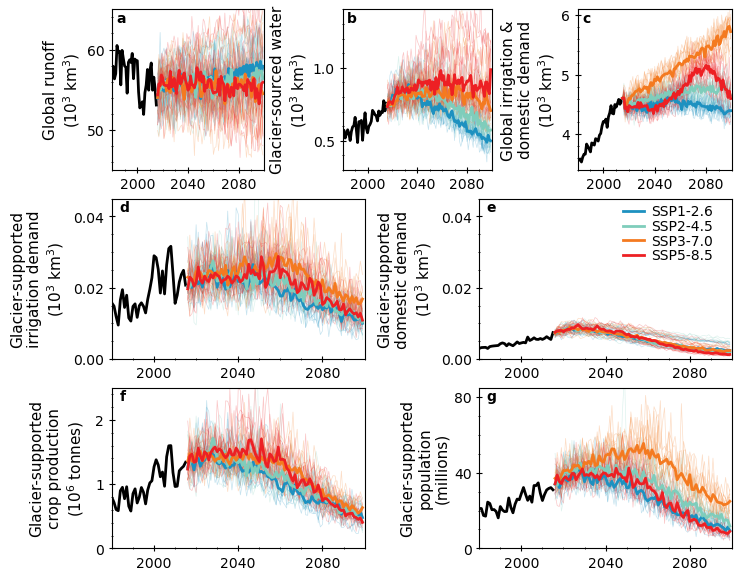

In [21]:
historical_yrs = list(range(1980,2016))

fig = plt.figure(figsize=(8, 7))

gs = gridspec.GridSpec(60, 600, figure=fig, hspace=0.2, wspace=6)

# First row: 3 subplots → 2 columns each
if demand_fn in ['annual_irr_plus_dom_water_demand_km3year.csv']:
    ax1 = fig.add_subplot(gs[0:18, 0:148])
    ax2 = fig.add_subplot(gs[0:18, 223:368])
    ax3 = fig.add_subplot(gs[0:18, 450:600])
else:
    ax1 = fig.add_subplot(gs[0:18, 0:155])
    ax2 = fig.add_subplot(gs[0:18, 230:385])
    ax3 = fig.add_subplot(gs[0:18, 445:600])

# Second row: 2 subplots → 3 columns each
ax4 = fig.add_subplot(gs[21:39, 0:245])
ax5 = fig.add_subplot(gs[21:39, 355:600])

# Third row: 2 subplots → 3 columns each
ax6 = fig.add_subplot(gs[42:60, 0:245])
ax7 = fig.add_subplot(gs[42:60, 355:600])



# ----- GLOBAL RUNOFF -----
# historical plot
ax1.plot(historical_yrs, runoff_hist/1e3, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    runoff_ssp_all = runoff_ssps_gcms[ssp]
    runoff_ssp_med = np.median(runoff_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        runoff_gcm = runoff_ssp_all[ngcm,:]
        ax1.plot(future_yrs, runoff_gcm/1e3, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax1.plot(future_yrs, runoff_ssp_med/1e3, color=ssp_colordict[ssp], lw=2, zorder=2)

ax1.set_ylabel('Global runoff\n(10$^{3}$ km$^{3}$)', size=11, labelpad=3)
ax1.set_xlim(1980,2100)
ax1.xaxis.set_major_locator(MultipleLocator(40))
ax1.xaxis.set_minor_locator(MultipleLocator(10))
ax1.set_ylim(45,65)
ax1.yaxis.set_major_locator(MultipleLocator(10))
ax1.yaxis.set_minor_locator(MultipleLocator(2))
ax1.text(0.03, 0.99, 'a', transform=ax1.transAxes, ha='left', va='top', fontweight='bold')


# ----- GLACIER RUNOFF -----
# historical plot
ax2.plot(historical_yrs, runoff_glacier_hist/1e3, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    runoff_glacier_ssp_all = runoff_glacier_ssps_gcms[ssp]
    runoff_glacier_ssp_med = np.median(runoff_glacier_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        runoff_glacier_gcm = runoff_glacier_ssp_all[ngcm,:]
        ax2.plot(future_yrs, runoff_glacier_gcm/1e3, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax2.plot(future_yrs, runoff_glacier_ssp_med/1e3, color=ssp_colordict[ssp], lw=2, zorder=2, label=ssp_name_dict[ssp])

ax2.set_ylabel('Glacier-sourced water\n(10$^{3}$ km$^{3}$)', size=11, labelpad=3)
ax2.set_xlim(1980,2100)
ax2.xaxis.set_major_locator(MultipleLocator(40))
ax2.xaxis.set_minor_locator(MultipleLocator(10))
ax2.set_ylim(0.3,1.4)
ax2.yaxis.set_major_locator(MultipleLocator(0.5))
ax2.yaxis.set_minor_locator(MultipleLocator(0.1))
ax2.text(0.03, 0.99, 'b', transform=ax2.transAxes, ha='left', va='top', fontweight='bold')


# ----- TOTAL DEMAND -----
# historical plot
ax3.plot(historical_yrs, demand_hist/1e3, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    demand_ssp_all = demand_ssps_gcms[ssp]
    demand_ssp_med = np.median(demand_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        demand_gcm = demand_ssp_all[ngcm,:]
        ax3.plot(future_yrs_demand, demand_gcm/1e3, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax3.plot(future_yrs_demand, demand_ssp_med/1e3, color=ssp_colordict[ssp], lw=2, zorder=2)

if demand_fn in ['annual_irr_plus_dom_water_demand_km3year.csv']:
    ax3.set_ylabel('Global irrigation &\ndomestic demand\n(10$^{3}$ km$^{3}$)', size=11, labelpad=3)
    ax3.set_ylim(3.4,6.1)
else:
    ax3.set_ylabel('Global demand\n(10$^{3}$ km$^{3}$)', size=11, labelpad=3)
    ax3.set_ylim(4.1,6.9)

ax3.set_xlim(1980,2100)
ax3.xaxis.set_major_locator(MultipleLocator(40))
ax3.xaxis.set_minor_locator(MultipleLocator(10))
ax3.yaxis.set_major_locator(MultipleLocator(1))
ax3.yaxis.set_minor_locator(MultipleLocator(0.2))
ax3.text(0.03, 0.99, 'c', transform=ax3.transAxes, ha='left', va='top', fontweight='bold')


# ----- GLACIER-to-DOMESTIC -----
# historical plot
ax5.plot(historical_yrs, runoff_glacier_municipal_hist/1e3, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    runoff_glacier_municipal_ssp_all = runoff_glacier_municipal_ssps_gcms[ssp]
    runoff_glacier_municipal_ssp_med = np.median(runoff_glacier_municipal_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        runoff_glacier_municipal_gcm = runoff_glacier_municipal_ssp_all[ngcm,:]
        ax5.plot(future_yrs, runoff_glacier_municipal_gcm/1e3, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax5.plot(future_yrs, runoff_glacier_municipal_ssp_med/1e3, color=ssp_colordict[ssp], lw=2, zorder=2, label=ssp_name_dict[ssp])

ax5.set_ylabel('Glacier-supported\ndomestic demand\n(10$^{3}$ km$^{3}$)', size=11, labelpad=5)
ax5.set_xlim(1980,2100)
ax5.xaxis.set_major_locator(MultipleLocator(40))
ax5.xaxis.set_minor_locator(MultipleLocator(10))
ax5.set_ylim(0,45/1e3)
ax5.yaxis.set_major_locator(MultipleLocator(20/1e3))
ax5.yaxis.set_minor_locator(MultipleLocator(5/1e3))
ax5.text(0.03, 0.99, 'e', transform=ax5.transAxes, ha='left', va='top', fontweight='bold')


# ----- PEOPLE EQUIVALENT -----
# historical plot
ax7.plot(historical_yrs, tot_pop_hist_annual/1e6, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    tot_pop_ssp_all = tot_pop_ssp_annual[ssp]/1e6
    tot_pop_ssp_med = np.median(tot_pop_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        tot_pop_ssp_gcm = tot_pop_ssp_all[ngcm,:]
        ax7.plot(future_yrs, tot_pop_ssp_gcm, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax7.plot(future_yrs, tot_pop_ssp_med, color=ssp_colordict[ssp], lw=2, zorder=2)

    print('ssp' + ssp, np.max(tot_pop_ssp_med))

ax7.set_ylabel('Glacier-supported\npopulation\n(millions)', size=11, labelpad=3)
ax7.set_xlim(1980,2100)
ax7.xaxis.set_major_locator(MultipleLocator(40))
ax7.xaxis.set_minor_locator(MultipleLocator(10))
ax7.set_ylim(0,85)
ax7.yaxis.set_major_locator(MultipleLocator(40))
ax7.yaxis.set_minor_locator(MultipleLocator(10))
ax7.text(0.03, 0.99, 'g', transform=ax7.transAxes, ha='left', va='top', fontweight='bold')


# ----- GLACIER-to-IRRIGATION -----
# historical plot
ax4.plot(historical_yrs, runoff_glacier_irr_hist/1e3, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    runoff_glacier_irr_ssp_all = runoff_glacier_irr_ssps_gcms[ssp]
    runoff_glacier_irr_ssp_med = np.median(runoff_glacier_irr_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        runoff_glacier_irr_gcm = runoff_glacier_irr_ssp_all[ngcm,:]
        ax4.plot(future_yrs, runoff_glacier_irr_gcm/1e3, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax4.plot(future_yrs, runoff_glacier_irr_ssp_med/1e3, color=ssp_colordict[ssp], lw=2, zorder=2)

ax4.set_ylabel('Glacier-supported\nirrigation demand\n(10$^{3}$ km$^{3}$)', size=11, labelpad=5)
ax4.set_xlim(1980,2100)
ax4.xaxis.set_major_locator(MultipleLocator(40))
ax4.xaxis.set_minor_locator(MultipleLocator(10))
ax4.set_ylim(0,45/1e3)
ax4.yaxis.set_major_locator(MultipleLocator(20/1e3))
ax4.yaxis.set_minor_locator(MultipleLocator(5/1e3))
ax4.text(0.03, 0.99, 'd', transform=ax4.transAxes, ha='left', va='top', fontweight='bold')


# ----- CROP PRODUCTION EQUIVALENT -----
# historical plot
ax6.plot(historical_yrs, irrProd_global_hist/1e9, color='k', lw=2)

# future plot
for ssp in wbm_ssps:
    irrProd_pg_ssp_all = irrProd_dict_ssps_gcms[ssp]/1e9  # convert to 10^9 kg, i.e., 10^6 tonnes
    irrProd_pg_ssp_med = np.median(irrProd_pg_ssp_all, axis=0)

    for ngcm, gcm in enumerate(gcm_names):
        irrProd_pg_ssp_gcm = irrProd_pg_ssp_all[ngcm,:]
        ax6.plot(future_yrs, irrProd_pg_ssp_gcm, color=ssp_colordict[ssp], lw=0.5, alpha=0.25, zorder=1)
        
    ax6.plot(future_yrs, irrProd_pg_ssp_med, color=ssp_colordict[ssp], lw=2, zorder=2, label=ssp_name_dict[ssp])

ax6.set_ylabel('Glacier-supported\ncrop production\n(10$^{6}$ tonnes)', size=11, labelpad=7)
ax6.set_xlim(1980,2100)
ax6.xaxis.set_major_locator(MultipleLocator(40))
ax6.xaxis.set_minor_locator(MultipleLocator(10))
ax6.set_ylim(0.0,2.5)
ax6.yaxis.set_major_locator(MultipleLocator(1))
ax6.yaxis.set_minor_locator(MultipleLocator(0.2))
ax6.text(0.03, 0.99, 'f', transform=ax6.transAxes, ha='left', va='top', fontweight='bold')


# Add legend
# ax2.legend(loc=(0.22,0.62), fontsize=10, ncol=1, columnspacing=0.5, labelspacing=0.1, 
            # handlelength=1, handletextpad=0.25, borderpad=0, frameon=False)
# ax3.legend(loc=(0.14,0.63), fontsize=10, ncol=1, columnspacing=0.5, labelspacing=0.05, 
#             handlelength=1, handletextpad=0.25, borderpad=0, frameon=False)
ax5.legend(loc=(0.57,0.60), fontsize=10, ncol=1, columnspacing=0.5, labelspacing=0.05, 
            handlelength=1.5, handletextpad=0.5, borderpad=0, frameon=False)
# ax7.legend(loc=(0.67,0.57), fontsize=10, ncol=1, columnspacing=0.5, labelspacing=0.25, 
            # handlelength=1, handletextpad=0.25, borderpad=0, frameon=False)

for ax in [ax1, ax2, ax3, ax4, ax5, ax6, ax7]:
    ax.tick_params(axis='both', which='major', direction='inout', length=4)
    ax.tick_params(axis='both', which='minor', direction='inout', length=2)

fig.set_size_inches(8,7)
fig.savefig(paper_fig_fp + 'fig1-global_statistics.png', bbox_inches='tight', dpi=300)

# Show the figure
plt.show()